Step 1: Load the CSVs and build the database

Load both CSVs with pandas, connect to a new store.db, and pour each DataFrame in as tables named orders and customers (Tutorial 1 pattern).

You should see: running pd.read_sql("SELECT name FROM sqlite_master", con) lists both tables.

In [1]:
import pandas as pd
import sqlite3

# 1. Load the CSV files into pandas DataFrames
df_orders = pd.read_csv('store_orders.csv')
df_customers = pd.read_csv('store_customers.csv')

# 2. Connect to a new SQLite database file named 'store.db'
con = sqlite3.connect('store.db')

# 3. Pour the DataFrames into the database as tables
df_orders.to_sql('orders', con, if_exists='replace', index=False)
df_customers.to_sql('customers', con, if_exists='replace', index=False)

# 4. Verify that both tables were created successfully
verification_query = "SELECT name FROM sqlite_master WHERE type='table';"
print(pd.read_sql(verification_query, con))

        name
0     orders
1  customers


Step 2: First look

Query the first 5 rows of orders (Tutorial 2 pattern).

You should see: 5 rows with order_id, customer_id, product, category, amount, order_date.

In [2]:
# Query the first 5 rows of the orders table
query = "SELECT * FROM orders LIMIT 5;"
df_preview = pd.read_sql(query, con)

# Display the resulting DataFrame
df_preview

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


Step 3: Filter and sort

Write one query returning all orders over 100 dollars, sorted by amount from highest to lowest (Tutorial 3 skeleton).

You should see: the top row is the seeded 499 dollar order.

In [3]:
# Query all orders over 100 dollars, sorted by amount from highest to lowest
query = """
SELECT * 
FROM orders 
WHERE amount > 100 
ORDER BY amount DESC;
"""

df_filtered = pd.read_sql(query, con)

# Display the resulting DataFrame
df_filtered
df_filtered

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


Step 4: Aggregate by category

One query: for each product category, the number of orders and the average amount, named with AS, sorted by average amount descending (Tutorial 4 pattern). In markdown, one sentence: which category earns the most per order?

You should see: one row per category with n and avg_amount columns.

In [4]:
query = """
SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC;
"""

df_category_summary = pd.read_sql(query, con)

df_category_summary

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Step 5: Join for spend by city

Write the JOIN (Tutorial 5 pattern): total spend per customer city, using the key the data dictionary gives you, sorted by total descending.

Hint: SUM of the order amount, grouped by the customers table’s city column.

You should see: a short table of cities with totals.

In [5]:
# Calculate total spend per customer city using a JOIN
query = """
SELECT c.city, SUM(o.amount) AS total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC;
"""

df_city_spend = pd.read_sql(query, con)

# Display the resulting DataFrame
df_city_spend

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


Step 6: The row-count audit (markdown cell)

Count the rows of orders and the rows your join produced (before grouping, or by summing order counts per city). They differ. Explain why in 2–3 sentences: the data contains 5 orders whose customer_id matches no customer.

The total row count of the original `orders` table is higher than the number of rows included in the `JOIN` result. 

This difference occurs because the dataset contains 5 orders whose `customer_id` values do not match any record in the `customers` table. 

Since a standard inner join only keeps rows where the key exists in both tables, these unmatched orders are automatically dropped.

Step 7: Chart a query result

Take your Step 5 result (already a DataFrame thanks to read_sql) and bar-chart total spend by city, fully labeled with title and units.

You should see: a labeled bar chart born from SQL.

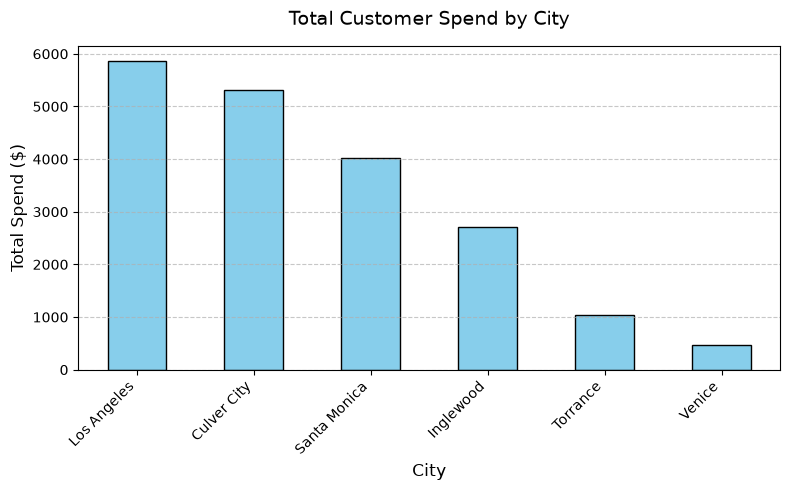

In [6]:
import matplotlib.pyplot as plt

chart_data = df_city_spend.set_index('city')

ax = chart_data['total_spend'].plot(kind='bar', color='skyblue', edgecolor='black', figsize=(8, 5))

plt.title('Total Customer Spend by City', fontsize=14, pad=15)
plt.xlabel('City', fontsize=12)
plt.ylabel('Total Spend ($)', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

Step 8: Your own question

Write one NEW business question about this data in plain English, then answer it with your own SQL query and state the answer in markdown.

Question: Which products generate the highest total revenue overall?

In [7]:
query = """
SELECT product, category, SUM(amount) AS total_revenue
FROM orders
GROUP BY product, category
ORDER BY total_revenue DESC
LIMIT 5;
"""

df_top_products = pd.read_sql(query, con)

df_top_products

,product,category,total_revenue
0,headset,electronics,4902.30
1,dock,electronics,3357.14
2,monitor,electronics,3174.73
3,shelf,furniture,3030.45
4,chair,furniture,2589.93


Step 9: Ethics note and safe push (markdown cell)

This database holds names and cities. In 2–3 sentences: what would you strip or aggregate before sharing results publicly, and why? Then make sure your notebook does NOT display a full dump of the customers table, and push only the notebook (never store.db or the customer CSV).

Before sharing results publicly, direct Personally Identifiable Information (PII) such as individual customer names and aggregate location data should be stripped to a broader level like state or region. This protects customer privacy and prevents the exposure of sensitive personal identifiers. 

As well, it is important to make sure that the notebook does not execute or display a full dump of the raw `customers` table. It is also essential to confirm that the `.gitignore` file excludes both `store.db` and the source CSV files so that only the `.ipynb` notebook file is pushed to version control.